In [38]:
import numpy as np
import matplotlib.pyplot as plt
import csv
import os 

In [13]:
def plotStandards(xlabel , ylabel):
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tick_params(axis='both', which='both', direction='in', right=True , labelright=True)
    plt.minorticks_on()
    plt.grid(True)
    plt.legend()


In [19]:
def loadnsave( filePath ):
    data1 = []
    data2 = []
    data3=  []
    with open(filePath) as csvDataFile:
        csvReader = csv.reader(csvDataFile)
        next(csvReader)# I don't think there is a preamble, I was wrong, it contains the column and row numbers
        for row in csvReader:
            data1.append( float(row[1]))
            data2.append(float(row[2]))
            data3.append(float(row[3]))
    return np.array(data1) , np.array(data2) , np.array(data3)
# first column time second column, then stage temp, then sample temp

time , stageTemp , sampleTemp = loadnsave(r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\data\414\4-14_equilibrium5VheaterCoil_19c.csv')


In [122]:

def plotFile( *args ):
    filePath = args[0]
    tempTime , tempStage , tempSample = loadnsave(filePath)
    fig = plt.figure()
    ax = fig.add_subplot()

    if len(args)>1:
        plt.plot( tempTime[args[1]:args[2]] , tempStage[args[1]:args[2]] , "b." , label="Stage Temperature")
        plt.plot( tempTime[args[1]:args[2]] , tempSample[args[1]:args[2]] , "r." , label="Sample Temperature")
        plt.title(filePath.split("datalist")[1][1:]   )
        plotStandards("Time (s)" , "Temperature (c)" )
    else:
        plt.plot( tempTime , tempStage , "b." , label="Stage Temperature")
        plt.plot( tempTime , tempSample , "r." , label="Sample Temperature")
        plt.title(filePath.split("datalist")[1][1:]   )
        plotStandards("Time (s)" , "Temperature (c)" )

#Single File test, will be used with directory list "listdir"
    
#plotFile(r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\datalist\4-14_equilibrium5VheaterCoil_19c.csv')

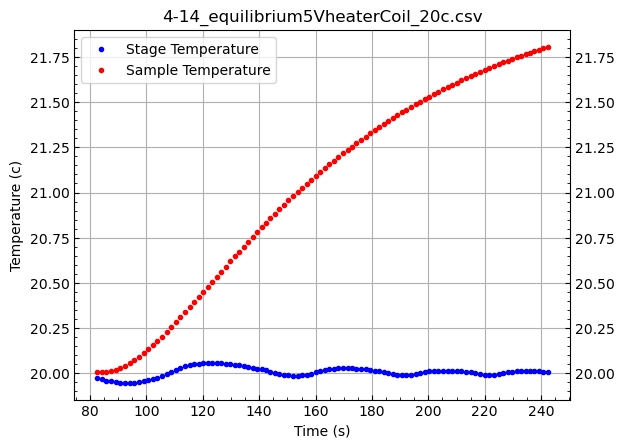

In [182]:
#raw strings with single backslashes or normal string with doublebackslashes which register as non escape characters
folder_path = r'C:\Users\Lawre\OneDrive\Desktop\gadolinium\datalist'
filenames = os.listdir(folder_path)

#Get indeces that correspond to linear sections
indeces = np.array([(87,145),(127,165),(50,150),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200),(0,200)])

no=2
start = "C:\\Users\\Lawre\\OneDrive\\Desktop\\gadolinium\\datalist"
file = filenames[no]
end = "\\"+file
totalFilePath = start+end
plotFile(totalFilePath , indeces[no][0] , indeces[no][1])

#for file in filenames:
    #start = "C:\\Users\\Lawre\\OneDrive\\Desktop\\gadolinium\\datalist"
    #end = "\\" + file
    #totalFilePath = start+end
    #Starting Index 100 ending index 150, if none passed then it just plots everything
    #plotFile(totalFilePath)
    #break